# Trabajo Práctico: Aprendizaje por Refuerzo en FrozenLake

## Instalar librerias

In [3]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from collections import deque
import random
import seaborn as sns
from IPython.display import clear_output
import warnings
warnings.filterwarnings('ignore')

## Reproducibilidad

In [ ]:
np.random.seed(42)
torch.manual_seed(42)
random.seed(42)

## Crear el entorno

In [ ]:
env = gym.make('FrozenLake-v1', desc=None, map_name="4x4", is_slippery=True, render_mode='ansi')
print("🏔️ ENTORNO FROZENLAKE")
print("=" * 50)
print(f"Número de estados: {env.observation_space.n}")
print(f"Número de acciones: {env.action_space.n}")
print(f"Acciones: {['Izquierda', 'Abajo', 'Derecha', 'Arriba']}")

🏔️ ENTORNO FROZENLAKE
Número de estados: 16
Número de acciones: 4
Acciones: ['Izquierda', 'Abajo', 'Derecha', 'Arriba']


## Mostrar el mapa

In [ ]:
print("\n🗺️ MAPA DEL ENTORNO:")
env.reset()
print(env.render())
print("\nLeyenda:")
print("S = Start (Inicio)")
print("F = Frozen (Hielo seguro)")
print("H = Hole (Hoyo - termina episodio)")
print("G = Goal (Objetivo - +1 recompensa)")


🗺️ MAPA DEL ENTORNO:

SFFF
FHFH
FFFH
HFFG


Leyenda:
S = Start (Inicio)
F = Frozen (Hielo seguro)
H = Hole (Hoyo - termina episodio)
G = Goal (Objetivo - +1 recompensa)


## Función para convertir estado numérico a posición (fila, columna)

In [ ]:

def estado_a_posicion(estado):
  return estado // 4, estado % 4

## Funcion para visualizar politica

In [ ]:
def visualizar_politica(policy, title="Política"):
  acciones_simbolos = ['←', '↓', '→', '↑']
  grid = np.array(acciones_simbolos)[policy].reshape(4, 4)
  plt.figure(figsize=(6, 6))
  plt.imshow(np.ones((4, 4)), cmap='Blues', alpha=0.3)

  for i in range(4):
      for j in range(4):
          estado = i * 4 + j
          if estado == 0:  # Start
              plt.text(j, i, f'S\n{grid[i,j]}', ha='center', va='center', fontsize=14, fontweight='bold')
          elif estado == 15:  # Goal
              plt.text(j, i, f'G\n{grid[i,j]}', ha='center', va='center', fontsize=14, fontweight='bold')
          elif estado in [5, 7, 11, 12]:  # Holes
              plt.text(j, i, f'H\n{grid[i,j]}', ha='center', va='center', fontsize=14, fontweight='bold', color='red')
          else:
              plt.text(j, i, grid[i,j], ha='center', va='center', fontsize=16)

  plt.xlim(-0.5, 3.5)
  plt.ylim(-0.5, 3.5)
  plt.xticks([])
  plt.yticks([])
  plt.title(title, fontsize=16)
  plt.grid(True, alpha=0.3)
  plt.show()

## Politica aleatoria

In [8]:
class PoliticaAleatoria:
  """Política que selecciona acciones completamente al azar"""
  def __init__(self, n_acciones):
      self.n_acciones = n_acciones
      self.nombre = "Política Aleatoria"

  def seleccionar_accion(self, estado):
      """Selecciona una acción aleatoria"""
      return np.random.randint(self.n_acciones)

  def entrenar(self, env, episodios=1000):
      """La política aleatoria no se entrena, solo evaluamos su desempeño"""
      print(f"🎲 Evaluando {self.nombre}...")
      recompensas = []
      exitos = 0

      for episodio in range(episodios):
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0

          while not terminado and pasos < 100:
              accion = self.seleccionar_accion(estado)
              estado, recompensa, terminado, truncated, _ = env.step(accion)
              recompensa_total += recompensa
              pasos += 1

              if truncated:
                  terminado = True

          if recompensa_total > 0:
              exitos += 1
          recompensas.append(recompensa_total)

          if (episodio + 1) % 200 == 0:
              tasa_exito = exitos / (episodio + 1)
              print(f"Episodio {episodio + 1}: Tasa de éxito = {tasa_exito:.3f}")

      tasa_exito_final = exitos / episodios
      print(f"\n📊 Resultados {self.nombre}:")
      print(f"Tasa de éxito final: {tasa_exito_final:.3f}")
      print(f"Recompensa promedio: {np.mean(recompensas):.3f}")

      return recompensas, tasa_exito_final

## Crear y evaluar política aleatoria

In [ ]:
agente_aleatorio = PoliticaAleatoria(env.action_space.n)
recompensas_aleatorio, tasa_exito_aleatorio = agente_aleatorio.entrenar(env, episodios=1000)

🎲 Evaluando Política Aleatoria...
Episodio 200: Tasa de éxito = 0.000
Episodio 400: Tasa de éxito = 0.007
Episodio 600: Tasa de éxito = 0.012
Episodio 800: Tasa de éxito = 0.014
Episodio 1000: Tasa de éxito = 0.014

📊 Resultados Política Aleatoria:
Tasa de éxito final: 0.014
Recompensa promedio: 0.014


## Visualizar política aleatoria (todas las acciones tienen la misma probabilidad)

In [ ]:

politica_aleatoria = np.random.randint(0, 4, 16)  # Solo para visualización

In [ ]:
politica_aleatoria

array([3, 0, 1, 2, 2, 1, 3, 3, 2, 2, 2, 0, 2, 0, 1, 3])

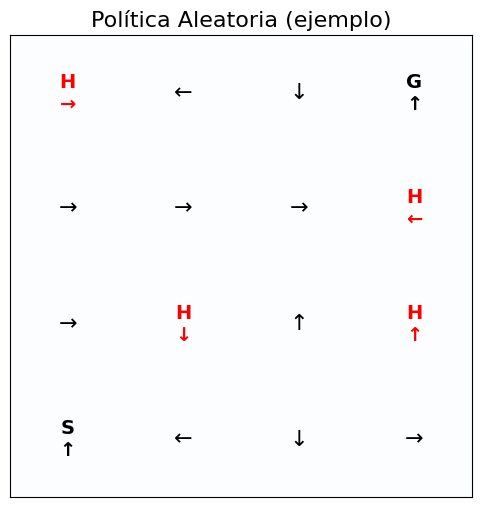

In [ ]:

visualizar_politica(politica_aleatoria, "Política Aleatoria (ejemplo)")

## Politica Q-learning

In [4]:
class QLearningTabular:
  """Implementación de Q-Learning con tabla Q explícita"""
  def __init__(self, n_estados, n_acciones, lr=0.1, gamma=0.95, epsilon=1.0):
      self.n_estados = n_estados
      self.n_acciones = n_acciones
      self.lr = lr  # learning rate
      self.gamma = gamma  # factor de descuento
      self.epsilon = epsilon  # exploración inicial
      self.epsilon_decay = 0.995
      self.epsilon_min = 0.01
      self.nombre = "Q-Learning Tabular"

      # Inicializar tabla Q
      self.q_table = np.zeros((n_estados, n_acciones))

      # Para tracking
      self.recompensas_entrenamiento = []
      self.epsilons = []

  def seleccionar_accion(self, estado, entrenando=True):
      """Selección de acción con epsilon-greedy"""
      if entrenando and np.random.random() < self.epsilon:
          return np.random.randint(self.n_acciones)  # Exploración
      else:
          return np.argmax(self.q_table[estado])  # Explotación

  def actualizar_q(self, estado, accion, recompensa, siguiente_estado, terminado):
      """Actualización de la tabla Q usando la ecuación de Bellman"""
      # Target Q-value
      if terminado:
          target = recompensa
      else:
          target = recompensa + self.gamma * np.max(self.q_table[siguiente_estado])

      # Actualización Q-Learning
      self.q_table[estado, accion] += self.lr * (target - self.q_table[estado, accion])

  def decay_epsilon(self):
      """Reducir epsilon gradualmente"""
      if self.epsilon > self.epsilon_min:
          self.epsilon *= self.epsilon_decay

  def obtener_politica(self):
      """Obtener la política greedy de la tabla Q"""
      return np.argmax(self.q_table, axis=1)

  def entrenar(self, env, episodios=10000):
      """Entrenamiento del agente Q-Learning"""
      print(f"🧠 Entrenando {self.nombre}...")

      recompensas = []
      exitos_ventana = deque(maxlen=100)  # Para promedios móviles

      for episodio in range(episodios):
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0

          while not terminado and pasos < 100:
              # Seleccionar acción
              accion = self.seleccionar_accion(estado, entrenando=True)

              # Ejecutar acción
              siguiente_estado, recompensa, terminado, truncated, _ = env.step(accion)

              if truncated:
                  terminado = True

              # Actualizar tabla Q
              self.actualizar_q(estado, accion, recompensa, siguiente_estado, terminado)

              recompensa_total += recompensa
              estado = siguiente_estado
              pasos += 1

          # Tracking
          recompensas.append(recompensa_total)
          exitos_ventana.append(1 if recompensa_total > 0 else 0)
          self.epsilons.append(self.epsilon)

          # Decay epsilon
          self.decay_epsilon()

          # Logging
          if (episodio + 1) % 1000 == 0:
              tasa_exito = np.mean(exitos_ventana) if len(exitos_ventana) > 0 else 0
              print(f"Episodio {episodio + 1}: Tasa éxito (últimos 100) = {tasa_exito:.3f}, Epsilon = {self.epsilon:.3f}")

      self.recompensas_entrenamiento = recompensas
      print(f"\n✅ Entrenamiento {self.nombre} completado!")

      return recompensas

  def evaluar(self, env, episodios=100):
      """Evaluación del agente entrenado sin exploración"""
      print(f"📊 Evaluando {self.nombre}...")

      exitos = 0
      recompensas = []
      pasos_totales = []

      for _ in range(episodios):
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0

          while not terminado and pasos < 100:
              accion = self.seleccionar_accion(estado, entrenando=False)  # Sin exploración
              estado, recompensa, terminado, truncated, _ = env.step(accion)

              if truncated:
                  terminado = True

              recompensa_total += recompensa
              pasos += 1

          if recompensa_total > 0:
              exitos += 1
          recompensas.append(recompensa_total)
          pasos_totales.append(pasos)

      tasa_exito = exitos / episodios
      print(f"Tasa de éxito: {tasa_exito:.3f}")
      print(f"Pasos promedio: {np.mean(pasos_totales):.1f}")

      return tasa_exito, recompensas

## Crear y entrenar agente Q-Learning

In [ ]:

agente_qlearning = QLearningTabular(env.observation_space.n, env.action_space.n,lr=0.1, gamma=0.95, epsilon=1.0)
recompensas_qlearning = agente_qlearning.entrenar(env, episodios=1000)

🧠 Entrenando Q-Learning Tabular...
Episodio 1000: Tasa éxito (últimos 100) = 0.600, Epsilon = 0.010

✅ Entrenamiento Q-Learning Tabular completado!


## Evaluar agente entrenado

In [ ]:

tasa_exito_qlearning, _ = agente_qlearning.evaluar(env, episodios=1000)


📊 Evaluando Q-Learning Tabular...
Tasa de éxito: 0.730
Pasos promedio: 41.6


## Visualizar política aprendida

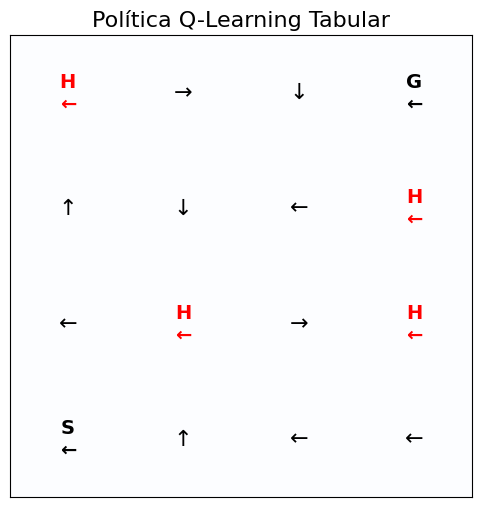

In [ ]:

politica_qlearning = agente_qlearning.obtener_politica()
visualizar_politica(politica_qlearning, "Política Q-Learning Tabular")

## Visualizar tabla Q como heatmap

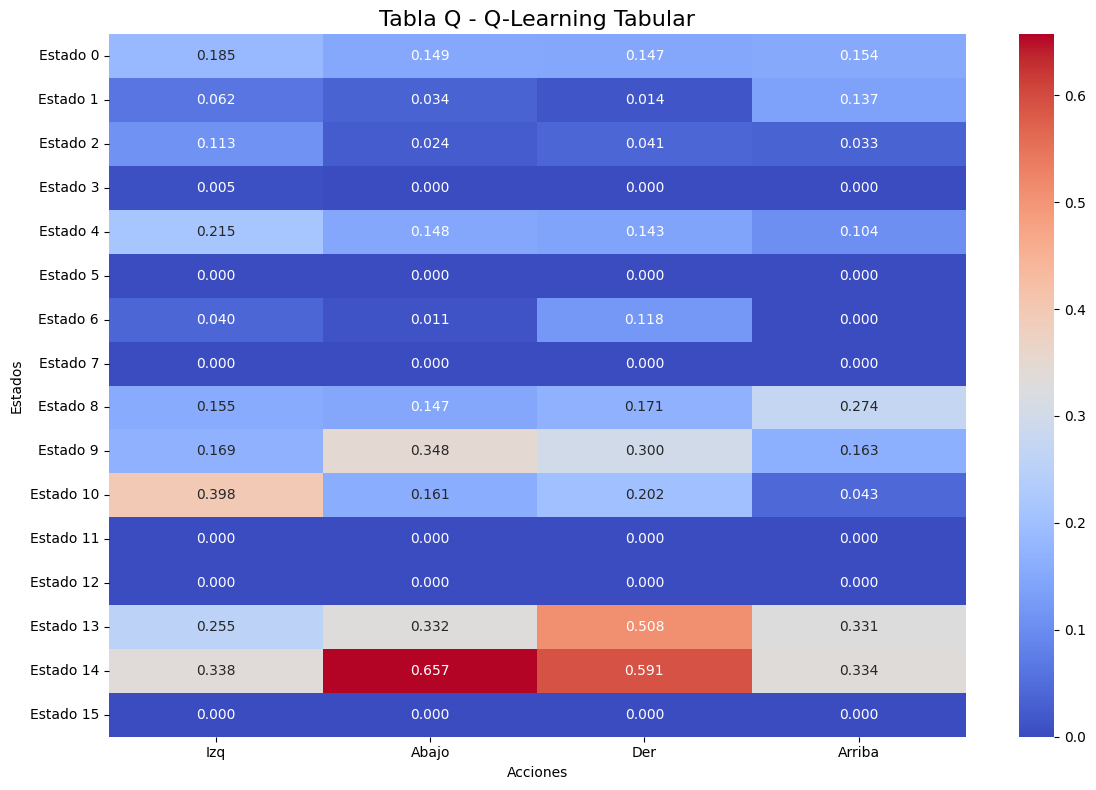

In [ ]:

plt.figure(figsize=(12, 8))
sns.heatmap(agente_qlearning.q_table, annot=True, fmt='.3f', cmap='coolwarm',
xticklabels=['Izq', 'Abajo', 'Der', 'Arriba'],
yticklabels=[f'Estado {i}' for i in range(16)])
plt.title('Tabla Q - Q-Learning Tabular', fontsize=16)
plt.xlabel('Acciones')
plt.ylabel('Estados')
plt.tight_layout()
plt.show()

## Mostrar valores Q para estados importantes
-

In [ ]:
print("🎯 VALORES Q PARA ESTADOS CLAVE:")
print("-" * 40)
estados_clave = [0, 5, 7, 11, 12, 14, 15]  # Start, Holes, Goal
acciones_nombres = ['Izquierda', 'Abajo', 'Derecha', 'Arriba']
for estado in estados_clave:
  if estado == 0:
    tipo = "START"
  elif estado == 15:
    tipo = "GOAL"
  elif estado in [5, 7, 11, 12]:
    tipo = "HOLE"
  else:
    tipo = "NORMAL"

print(f"\nEstado {estado} ({tipo}):")
for accion, valor in enumerate(agente_qlearning.q_table[estado]):
    print(f"  {acciones_nombres[accion]}: {valor:.3f}")

🎯 VALORES Q PARA ESTADOS CLAVE:
----------------------------------------

Estado 15 (GOAL):
  Izquierda: 0.000
  Abajo: 0.000
  Derecha: 0.000
  Arriba: 0.000


# Deep Q-Network

## red DQN

In [8]:
class DQN(nn.Module):
  """Red neuronal para aproximar la función Q"""
  def __init__(self, input_size, hidden_size, output_size):
      super(DQN, self).__init__()
      self.network = nn.Sequential(
          nn.Linear(input_size, hidden_size),
          nn.ReLU(),
          nn.Linear(hidden_size, hidden_size),
          nn.ReLU(),
          nn.Linear(hidden_size, output_size)
      )

  def forward(self, x):
      return self.network(x)

## DQNAgent

In [5]:
class DQNAgent:
  """Agente Deep Q-Network con Experience Replay y Target Network"""
  def __init__(self, state_size, action_size, lr=0.001, gamma=0.95, epsilon=1.0):
      self.state_size = state_size
      self.action_size = action_size
      self.gamma = gamma
      self.epsilon = epsilon
      self.epsilon_decay = 0.995
      self.epsilon_min = 0.01
      self.learning_rate = lr
      self.nombre = "Deep Q-Network (DQN)"

      # Configuración del dispositivo
      self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
      print(f"🖥️ Usando dispositivo: {self.device}")

      # Redes neuronales
      hidden_size = 128
      self.q_network = DQN(state_size, hidden_size, action_size).to(self.device)
      self.target_network = DQN(state_size, hidden_size, action_size).to(self.device)
      self.optimizer = optim.Adam(self.q_network.parameters(), lr=lr)

      # Inicializar target network con mismos pesos
      self.update_target_network()

      # Experience Replay
      self.memory = deque(maxlen=10000)
      self.batch_size = 32

      # Frecuencia de actualización de target network
      self.update_target_frequency = 100
      self.step_count = 0

      # Para tracking
      self.losses = []
      self.recompensas_entrenamiento = []
      self.epsilons = []

  def state_to_onehot(self, state):
      """Convertir estado discreto a representación one-hot"""
      onehot = np.zeros(self.state_size)
      onehot[state] = 1.0
      return onehot

  def remember(self, estado, accion, recompensa, siguiente_estado, terminado):
      """Almacenar experiencia en el buffer de replay"""
      estado_onehot = self.state_to_onehot(estado)
      siguiente_estado_onehot = self.state_to_onehot(siguiente_estado)

      self.memory.append((estado_onehot, accion, recompensa, siguiente_estado_onehot, terminado))

  def seleccionar_accion(self, estado, entrenando=True):
      """Selección de acción epsilon-greedy usando la red neuronal"""
      if entrenando and np.random.random() < self.epsilon:
          return random.randrange(self.action_size)

      # Convertir estado a tensor
      estado_onehot = self.state_to_onehot(estado)
      estado_tensor = torch.FloatTensor(estado_onehot).unsqueeze(0).to(self.device)

      # Forward pass
      with torch.no_grad():
          q_values = self.q_network(estado_tensor)

      return np.argmax(q_values.cpu().data.numpy())

  def replay(self):
      """Experience replay para entrenar la red"""
      if len(self.memory) < self.batch_size:
          return

      # Muestrear batch aleatorio
      batch = random.sample(self.memory, self.batch_size)
      estados = torch.FloatTensor([e[0] for e in batch]).to(self.device)
      acciones = torch.LongTensor([e[1] for e in batch]).to(self.device)
      recompensas = torch.FloatTensor([e[2] for e in batch]).to(self.device)
      siguientes_estados = torch.FloatTensor([e[3] for e in batch]).to(self.device)
      terminados = torch.BoolTensor([e[4] for e in batch]).to(self.device)

      # Q-values actuales
      current_q_values = self.q_network(estados).gather(1, acciones.unsqueeze(1))

      # Q-values objetivo usando target network
      with torch.no_grad():
          next_q_values = self.target_network(siguientes_estados).max(1)[0]
          target_q_values = recompensas + (self.gamma * next_q_values * ~terminados)

      # Calcular pérdida
      loss = F.mse_loss(current_q_values.squeeze(), target_q_values)

      # Backpropagation
      self.optimizer.zero_grad()
      loss.backward()
      self.optimizer.step()

      # Guardar pérdida para análisis
      self.losses.append(loss.item())

  def update_target_network(self):
      """Actualizar la target network con pesos de la red principal"""
      self.target_network.load_state_dict(self.q_network.state_dict())

  def decay_epsilon(self):
      """Reducir epsilon gradualmente"""
      if self.epsilon > self.epsilon_min:
          self.epsilon *= self.epsilon_decay

  def obtener_politica(self):
      """Obtener política greedy de la red entrenada"""
      politica = []
      for estado in range(self.state_size):
          accion = self.seleccionar_accion(estado, entrenando=False)
          politica.append(accion)
      return np.array(politica)

  def entrenar(self, env, episodios=2000):
      """Entrenamiento del agente DQN"""
      print(f"🤖 Entrenando {self.nombre}...")

      recompensas = []
      exitos_ventana = deque(maxlen=100)

      for episodio in range(episodios):
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0

          while not terminado and pasos < 100:
              # Seleccionar acción
              accion = self.seleccionar_accion(estado, entrenando=True)

              # Ejecutar acción
              siguiente_estado, recompensa, terminado, truncated, _ = env.step(accion)

              if truncated:
                  terminado = True

              # Almacenar experiencia
              self.remember(estado, accion, recompensa, siguiente_estado, terminado)

              # Entrenar la red
              self.replay()

              recompensa_total += recompensa
              estado = siguiente_estado
              pasos += 1
              self.step_count += 1

              # Actualizar target network periódicamente
              if self.step_count % self.update_target_frequency == 0:
                  self.update_target_network()

          # Tracking
          recompensas.append(recompensa_total)
          exitos_ventana.append(1 if recompensa_total > 0 else 0)
          self.epsilons.append(self.epsilon)

          # Decay epsilon
          self.decay_epsilon()

          # Logging
          if (episodio + 1) % 200 == 0:
              tasa_exito = np.mean(exitos_ventana) if len(exitos_ventana) > 0 else 0
              loss_promedio = np.mean(self.losses[-100:]) if len(self.losses) > 0 else 0
              print(f"Episodio {episodio + 1}: Tasa éxito = {tasa_exito:.3f}, "
                    f"Epsilon = {self.epsilon:.3f}, Loss = {loss_promedio:.4f}")

      self.recompensas_entrenamiento = recompensas
      print(f"\n✅ Entrenamiento {self.nombre} completado!")

      return recompensas

  def evaluar(self, env, episodios=100):
      """Evaluación del agente entrenado"""
      print(f"📊 Evaluando {self.nombre}...")

      exitos = 0
      recompensas = []
      pasos_totales = []

      for _ in range(episodios):
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0

          while not terminado and pasos < 100:
              accion = self.seleccionar_accion(estado, entrenando=False)
              estado, recompensa, terminado, truncated, _ = env.step(accion)

              if truncated:
                  terminado = True

              recompensa_total += recompensa
              pasos += 1

          if recompensa_total > 0:
              exitos += 1
          recompensas.append(recompensa_total)
          pasos_totales.append(pasos)

      tasa_exito = exitos / episodios
      print(f"Tasa de éxito: {tasa_exito:.3f}")
      print(f"Pasos promedio: {np.mean(pasos_totales):.1f}")

      return tasa_exito, recompensas

## Entrenar deep DQN

In [ ]:
agente_dqn = DQNAgent(env.observation_space.n, env.action_space.n,
lr=0.001, gamma=0.95, epsilon=1.0)
recompensas_dqn = agente_dqn.entrenar(env, episodios=2000)

🖥️ Usando dispositivo: cpu
🤖 Entrenando Deep Q-Network (DQN)...
Episodio 200: Tasa éxito = 0.070, Epsilon = 0.367, Loss = 0.0074
Episodio 400: Tasa éxito = 0.210, Epsilon = 0.135, Loss = 0.0073
Episodio 600: Tasa éxito = 0.460, Epsilon = 0.049, Loss = 0.0085
Episodio 800: Tasa éxito = 0.560, Epsilon = 0.018, Loss = 0.0076
Episodio 1000: Tasa éxito = 0.630, Epsilon = 0.010, Loss = 0.0074
Episodio 1200: Tasa éxito = 0.560, Epsilon = 0.010, Loss = 0.0076
Episodio 1400: Tasa éxito = 0.640, Epsilon = 0.010, Loss = 0.0087
Episodio 1600: Tasa éxito = 0.520, Epsilon = 0.010, Loss = 0.0084
Episodio 1800: Tasa éxito = 0.550, Epsilon = 0.010, Loss = 0.0081
Episodio 2000: Tasa éxito = 0.510, Epsilon = 0.010, Loss = 0.0082

✅ Entrenamiento Deep Q-Network (DQN) completado!


## Evaluar agente Deep DQN

In [ ]:
tasa_exito_dqn, _ = agente_dqn.evaluar(env, episodios=1000)


📊 Evaluando Deep Q-Network (DQN)...
Tasa de éxito: 0.603
Pasos promedio: 36.2


In [ ]:
tasa_exito_dqn, _ = agente_dqn.evaluar(env, episodios=1000)

## Visualizar política aprendida

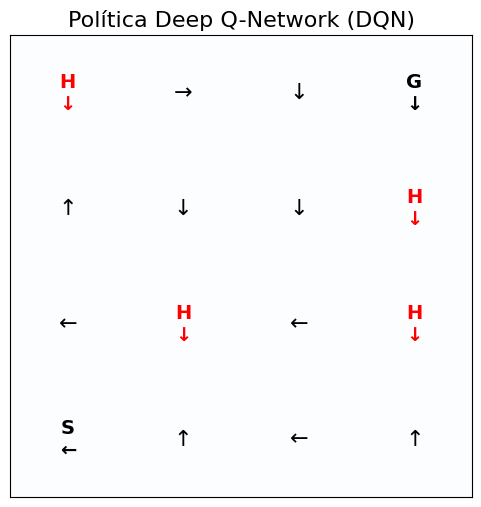

In [ ]:

politica_dqn = agente_dqn.obtener_politica()
visualizar_politica(politica_dqn, "Política Deep Q-Network (DQN)")


# Comparación de resultados

## Comparación final tasa de éxito

In [ ]:
print("🏆 COMPARACIÓN FINAL DE AGENTES")
print("=" * 50)
print(f"Política Aleatoria:    Tasa de éxito = {tasa_exito_aleatorio:.3f}")
print(f"Q-Learning Tabular:    Tasa de éxito = {tasa_exito_qlearning:.3f}")
print(f"Deep Q-Network (DQN):  Tasa de éxito = {tasa_exito_dqn:.3f}")

🏆 COMPARACIÓN FINAL DE AGENTES
Política Aleatoria:    Tasa de éxito = 0.014
Q-Learning Tabular:    Tasa de éxito = 0.730
Deep Q-Network (DQN):  Tasa de éxito = 0.603


## Crear gráficas de comparación


Crear gráficas de comparación


### 1. Curvas de aprendizaje

In [ ]:
len(recompensas_aleatorio)

1000

In [ ]:
len(recompensas_qlearning)

1000

In [ ]:
len(recompensas_dqn)

1000

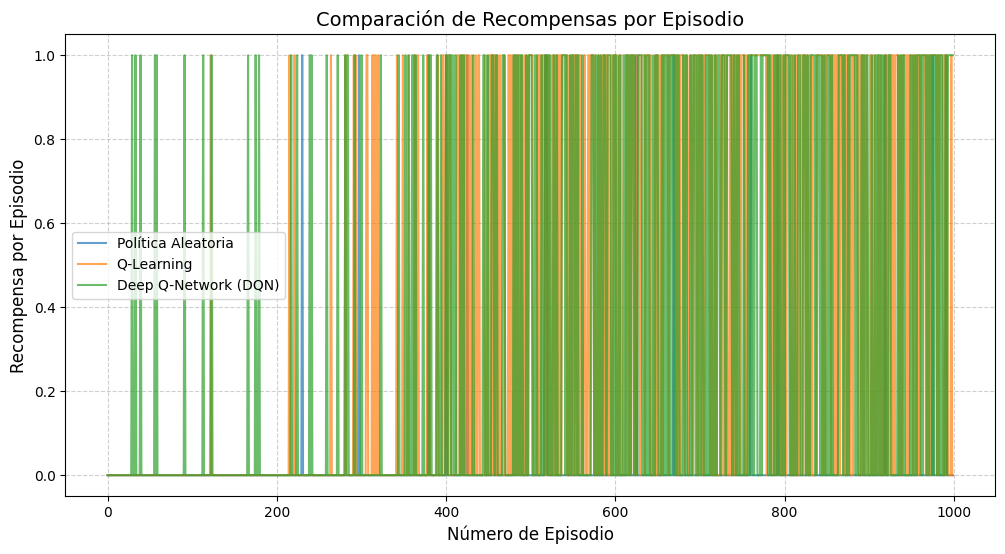

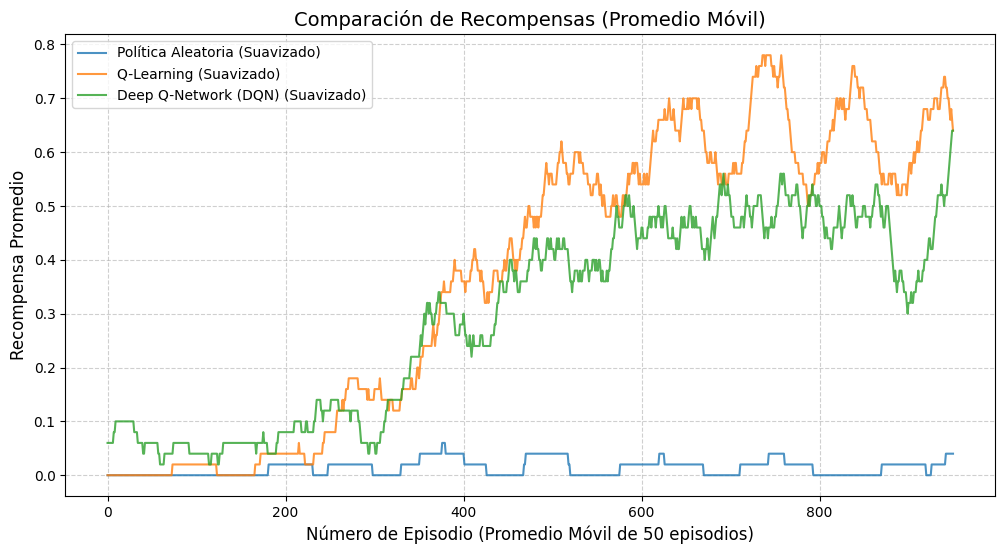

In [ ]:
# prompt: crear gráfico que compare recompensas_aleatorio, recompensas_qlearning y recompensas_dqn. Eje x es nro de episodio y el eje Y valor de la recompensa

import matplotlib.pyplot as plt
import numpy as np
# Asegurar que las listas de recompensas tengan la misma longitud para la gráfica
# Tomaremos la longitud mínima si son diferentes
min_len = min(len(recompensas_aleatorio), len(recompensas_qlearning), len(recompensas_dqn))

plt.figure(figsize=(12, 6))
plt.plot(recompensas_aleatorio[:min_len], label='Política Aleatoria', alpha=0.7)
plt.plot(recompensas_qlearning[:min_len], label='Q-Learning', alpha=0.7)
plt.plot(recompensas_dqn[:min_len], label='Deep Q-Network (DQN)', alpha=0.7)

plt.xlabel('Número de Episodio', fontsize=12)
plt.ylabel('Recompensa por Episodio', fontsize=12)
plt.title('Comparación de Recompensas por Episodio', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Para suavizar la gráfica, se puede usar un promedio móvil
def moving_average(data, window_size):
    if len(data) < window_size:
        return data
    return np.convolve(data, np.ones(window_size)/window_size, mode='valid')

window = 50  # Tamaño de la ventana para el promedio móvil

recompensas_aleatorio_suavizado = moving_average(recompensas_aleatorio, window)
recompensas_qlearning_suavizado = moving_average(recompensas_qlearning, window)
recompensas_dqn_suavizado = moving_average(recompensas_dqn, window)

# Ajustar la longitud mínima para las series suavizadas
min_len_suavizado = min(len(recompensas_aleatorio_suavizado), len(recompensas_qlearning_suavizado), len(recompensas_dqn_suavizado))

plt.figure(figsize=(12, 6))
plt.plot(recompensas_aleatorio_suavizado[:min_len_suavizado], label='Política Aleatoria (Suavizado)', alpha=0.8)
plt.plot(recompensas_qlearning_suavizado[:min_len_suavizado], label='Q-Learning (Suavizado)', alpha=0.8)
plt.plot(recompensas_dqn_suavizado[:min_len_suavizado], label='Deep Q-Network (DQN) (Suavizado)', alpha=0.8)

plt.xlabel(f'Número de Episodio (Promedio Móvil de {window} episodios)', fontsize=12)
plt.ylabel('Recompensa Promedio', fontsize=12)
plt.title('Comparación de Recompensas (Promedio Móvil)', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()



### 2. Comparación de tasas de éxito

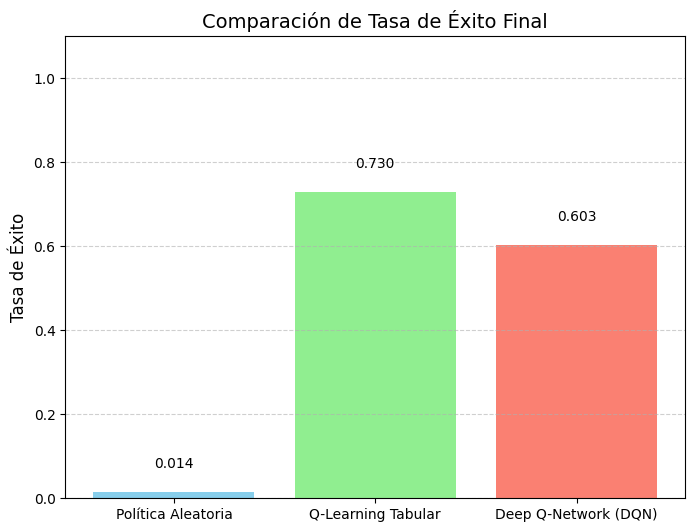

In [ ]:
# prompt: comparar tasa_exito_aleatorio, tasa_exito_qlearning, tasa_exito_dqn en un gráfico de barras

import matplotlib.pyplot as plt
metricas = ['Política Aleatoria', 'Q-Learning Tabular', 'Deep Q-Network (DQN)']
tasas_exito = [tasa_exito_aleatorio, tasa_exito_qlearning, tasa_exito_dqn]

plt.figure(figsize=(8, 6))
barras = plt.bar(metricas, tasas_exito, color=['skyblue', 'lightgreen', 'salmon'])
plt.ylabel('Tasa de Éxito', fontsize=12)
plt.title('Comparación de Tasa de Éxito Final', fontsize=14)
plt.ylim(0, 1.1) # Limitar el eje Y de 0 a 1.1 para mejor visualización

# Añadir los valores de las tasas de éxito encima de cada barra
for bar in barras:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.05, f'{yval:.3f}', ha='center', va='bottom', fontsize=10)

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()


### Evolución de Epsilon (solo para algoritmos que usan exploración)

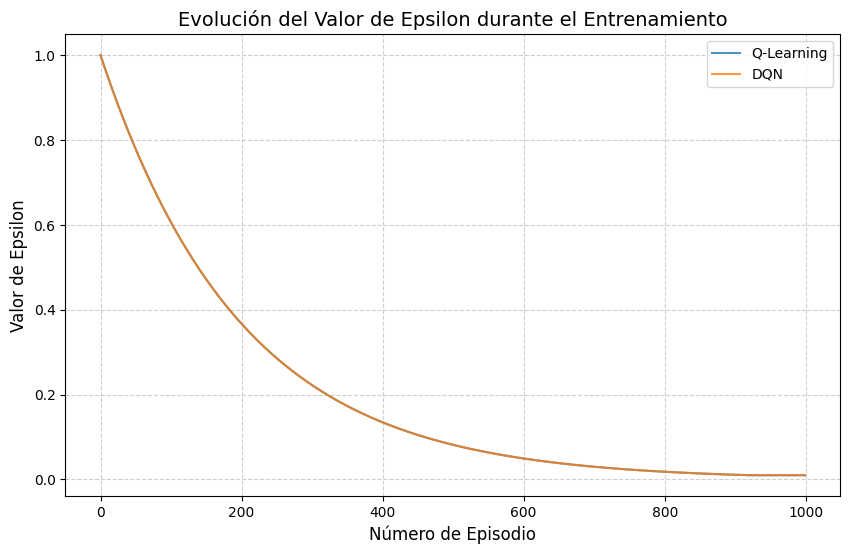

In [ ]:
# prompt: Crear un gráfico para comparar agente_qlearning.epsilons y agente_qlearning.epsilons siendo x el nro de episodios y el eje Y el valor de epsilon

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.plot(agente_qlearning.epsilons, label='Q-Learning', alpha=0.8)
plt.plot(agente_dqn.epsilons, label='DQN', alpha=0.8)

plt.xlabel('Número de Episodio', fontsize=12)
plt.ylabel('Valor de Epsilon', fontsize=12)
plt.title('Evolución del Valor de Epsilon durante el Entrenamiento', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### DQN pérdida

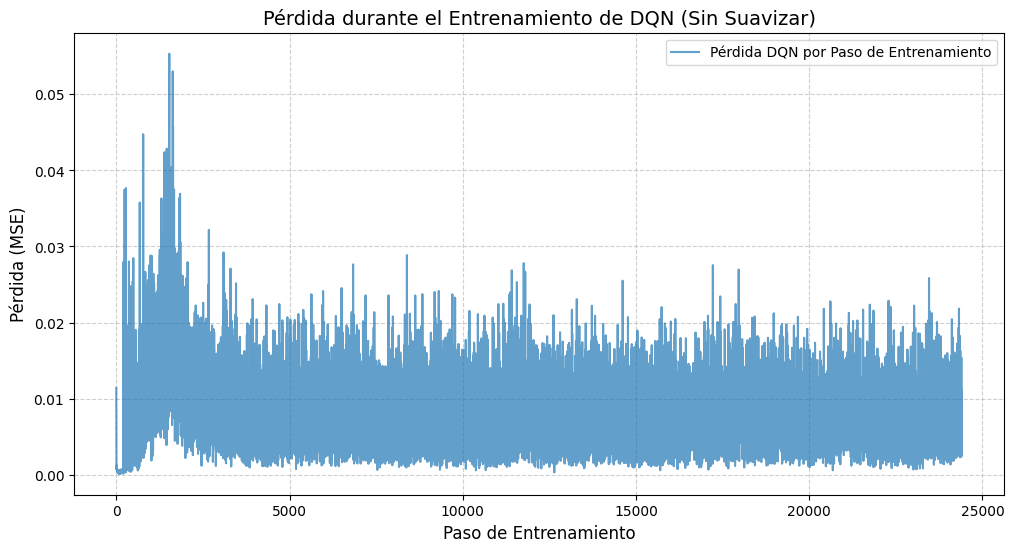

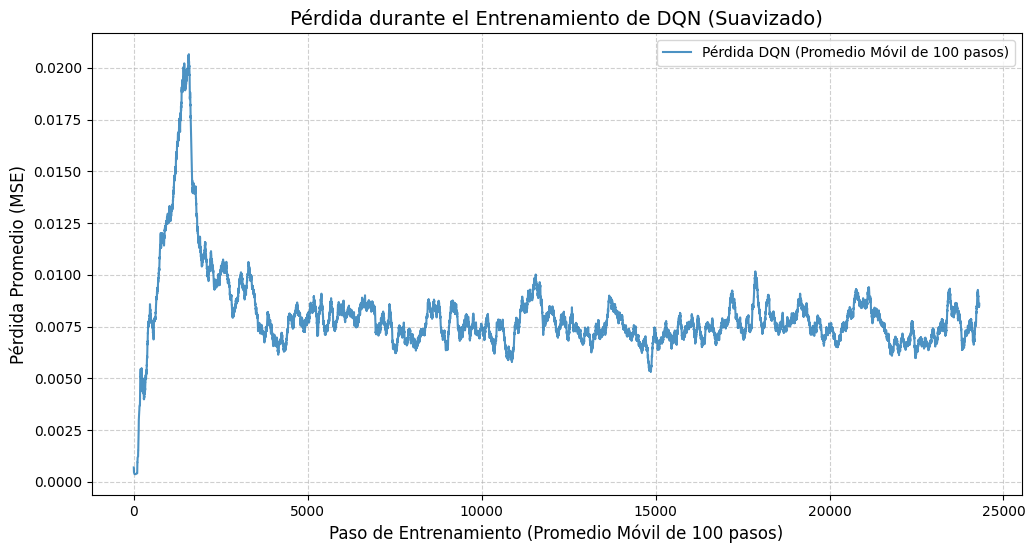

In [ ]:
# prompt: Graficar agente_dqn.losses que representa la pérdida durante el entrenamiento de DQN. Mostrar con y sin promedio móvil

import matplotlib.pyplot as plt
# Graficar la pérdida del agente DQN
plt.figure(figsize=(12, 6))
plt.plot(agente_dqn.losses, label='Pérdida DQN por Paso de Entrenamiento', alpha=0.7)
plt.xlabel('Paso de Entrenamiento', fontsize=12)
plt.ylabel('Pérdida (MSE)', fontsize=12)
plt.title('Pérdida durante el Entrenamiento de DQN (Sin Suavizar)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

# Graficar la pérdida con promedio móvil para suavizar
window_loss = 100 # Tamaño de la ventana para el promedio móvil de la pérdida
losses_dqn_suavizado = moving_average(agente_dqn.losses, window_loss)

plt.figure(figsize=(12, 6))
plt.plot(losses_dqn_suavizado, label=f'Pérdida DQN (Promedio Móvil de {window_loss} pasos)', alpha=0.8)
plt.xlabel(f'Paso de Entrenamiento (Promedio Móvil de {window_loss} pasos)', fontsize=12)
plt.ylabel('Pérdida Promedio (MSE)', fontsize=12)
plt.title('Pérdida durante el Entrenamiento de DQN (Suavizado)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

# Ejercitación

## A) Modifique el entrenamiento de los agentes para entrenar por más episodios. Evalue su desempeño. ¿ Mejora o empeora ?






# Introducción – Consigna A

En este experimento vamos a analizar cómo influye la cantidad de episodios de entrenamiento en el desempeño de los tres agentes: política aleatoria, Q-Learning y DQN.

Para ello, aumentamos los episodios respecto de la configuración original y comparamos sus tasas de éxito. El objetivo es observar si entrenar durante más tiempo mejora el aprendizaje de los agentes y qué diferencias existen entre los distintos métodos.

In [10]:

# CONSIGNA A - Función de evaluación

def evaluar_A(agente, episodios=1000):
    env_eval = gym.make(
        'FrozenLake-v1',
        map_name='4x4',
        is_slippery=True
    )

    env_eval.reset(seed=123)

    tasa_exito, _ = agente.evaluar(
        env_eval, episodios=episodios
    )

    env_eval.close()
    return tasa_exito


In [10]:

# CONSIGNA A - Política Aleatoria

def experimentar_aleatorio(episodios):
    np.random.seed(42)

    env_a = gym.make(
        'FrozenLake-v1',
        map_name='4x4',
        is_slippery=True
    )
    env_a.reset(seed=42)

    agente_a = PoliticaAleatoria(env_a.action_space.n)

    _, tasa_exito = agente_a.entrenar(
        env_a, episodios=episodios
    )

    env_a.close()
    return tasa_exito


# Comparación
exito_a_1000 = experimentar_aleatorio(1000)
exito_a_10000 = experimentar_aleatorio(10000)


print("\nRESULTADOS POLÍTICA ALEATORIA")
print(f"1000 episodios:  {exito_a_1000:.1%}")
print(f"10000 episodios: {exito_a_10000:.1%}")



🎲 Evaluando Política Aleatoria...
Episodio 200: Tasa de éxito = 0.020
Episodio 400: Tasa de éxito = 0.015
Episodio 600: Tasa de éxito = 0.013
Episodio 800: Tasa de éxito = 0.013
Episodio 1000: Tasa de éxito = 0.010

📊 Resultados Política Aleatoria:
Tasa de éxito final: 0.010
Recompensa promedio: 0.010
🎲 Evaluando Política Aleatoria...
Episodio 200: Tasa de éxito = 0.020
Episodio 400: Tasa de éxito = 0.015
Episodio 600: Tasa de éxito = 0.013
Episodio 800: Tasa de éxito = 0.013
Episodio 1000: Tasa de éxito = 0.010
Episodio 1200: Tasa de éxito = 0.011
Episodio 1400: Tasa de éxito = 0.014
Episodio 1600: Tasa de éxito = 0.014
Episodio 1800: Tasa de éxito = 0.013
Episodio 2000: Tasa de éxito = 0.013
Episodio 2200: Tasa de éxito = 0.013
Episodio 2400: Tasa de éxito = 0.013
Episodio 2600: Tasa de éxito = 0.015
Episodio 2800: Tasa de éxito = 0.014
Episodio 3000: Tasa de éxito = 0.015
Episodio 3200: Tasa de éxito = 0.016
Episodio 3400: Tasa de éxito = 0.016
Episodio 3600: Tasa de éxito = 0.016
E

In [9]:

# CONSIGNA A - Q-Learning

np.random.seed(42)
random.seed(42)

env_q_a = gym.make(
    'FrozenLake-v1',
    map_name='4x4',
    is_slippery=True
)
env_q_a.reset(seed=42)

agente_q_a = QLearningTabular(
    env_q_a.observation_space.n,
    env_q_a.action_space.n,
    lr=0.1,
    gamma=0.95,
    epsilon=1.0
)

# Primer entrenamiento: 1000 episodios
agente_q_a.entrenar(env_q_a, episodios=1000)
exito_q_1000 = evaluar_A(agente_q_a)

# Continuamos 9000 episodios adicionales
agente_q_a.entrenar(env_q_a, episodios=9000)
exito_q_10000 = evaluar_A(agente_q_a)

env_q_a.close()

print("\nRESULTADOS Q-LEARNING")
print(f"1000 episodios:  {exito_q_1000:.1%}")
print(f"10000 episodios: {exito_q_10000:.1%}")


🧠 Entrenando Q-Learning Tabular...
Episodio 1000: Tasa éxito (últimos 100) = 0.090, Epsilon = 0.010

✅ Entrenamiento Q-Learning Tabular completado!
📊 Evaluando Q-Learning Tabular...
Tasa de éxito: 0.090
Pasos promedio: 10.5
🧠 Entrenando Q-Learning Tabular...
Episodio 1000: Tasa éxito (últimos 100) = 0.070, Epsilon = 0.010
Episodio 2000: Tasa éxito (últimos 100) = 0.170, Epsilon = 0.010
Episodio 3000: Tasa éxito (últimos 100) = 0.210, Epsilon = 0.010
Episodio 4000: Tasa éxito (últimos 100) = 0.200, Epsilon = 0.010
Episodio 5000: Tasa éxito (últimos 100) = 0.470, Epsilon = 0.010
Episodio 6000: Tasa éxito (últimos 100) = 0.680, Epsilon = 0.010
Episodio 7000: Tasa éxito (últimos 100) = 0.540, Epsilon = 0.010
Episodio 8000: Tasa éxito (últimos 100) = 0.460, Epsilon = 0.010
Episodio 9000: Tasa éxito (últimos 100) = 0.540, Epsilon = 0.010

✅ Entrenamiento Q-Learning Tabular completado!
📊 Evaluando Q-Learning Tabular...
Tasa de éxito: 0.744
Pasos promedio: 40.3

RESULTADOS Q-LEARNING
1000 epis

In [19]:

# CONSIGNA A - Deep Q-Network

np.random.seed(42)
random.seed(42)
torch.manual_seed(42)

env_dqn_a = gym.make(
    'FrozenLake-v1',
    map_name='4x4',
    is_slippery=True
)
env_dqn_a.reset(seed=42)

agente_dqn_a = DQNAgent(
    env_dqn_a.observation_space.n,
    env_dqn_a.action_space.n,
    lr=0.001,
    gamma=0.95,
    epsilon=1.0
)

# Primer entrenamiento: 2000 episodios
agente_dqn_a.entrenar(env_dqn_a, episodios=2000)
exito_dqn_2000 = evaluar_A(agente_dqn_a)

# Continuamos hasta completar 10000 episodios
agente_dqn_a.entrenar(env_dqn_a, episodios=8000)
exito_dqn_10000 = evaluar_A(agente_dqn_a)

env_dqn_a.close()

print("\nRESULTADOS DQN")
print(f"2000 episodios: {exito_dqn_2000:.1%}")
print(f"10000 episodios: {exito_dqn_10000:.1%}")


🖥️ Usando dispositivo: cpu
🤖 Entrenando Deep Q-Network (DQN)...
Episodio 200: Tasa éxito = 0.030, Epsilon = 0.367, Loss = 0.0054
Episodio 400: Tasa éxito = 0.190, Epsilon = 0.135, Loss = 0.0074
Episodio 600: Tasa éxito = 0.420, Epsilon = 0.049, Loss = 0.0064
Episodio 800: Tasa éxito = 0.570, Epsilon = 0.018, Loss = 0.0075
Episodio 1000: Tasa éxito = 0.600, Epsilon = 0.010, Loss = 0.0091
Episodio 1200: Tasa éxito = 0.670, Epsilon = 0.010, Loss = 0.0076
Episodio 1400: Tasa éxito = 0.660, Epsilon = 0.010, Loss = 0.0078
Episodio 1600: Tasa éxito = 0.680, Epsilon = 0.010, Loss = 0.0078
Episodio 1800: Tasa éxito = 0.580, Epsilon = 0.010, Loss = 0.0075
Episodio 2000: Tasa éxito = 0.600, Epsilon = 0.010, Loss = 0.0070

✅ Entrenamiento Deep Q-Network (DQN) completado!
📊 Evaluando Deep Q-Network (DQN)...
Tasa de éxito: 0.228
Pasos promedio: 15.1
🤖 Entrenando Deep Q-Network (DQN)...
Episodio 200: Tasa éxito = 0.490, Epsilon = 0.010, Loss = 0.0084
Episodio 400: Tasa éxito = 0.610, Epsilon = 0.010,

COMPARACIÓN FINAL - CONSIGNA A
-------------------------------------------------------
Agente               Inicial     Ampliado
-------------------------------------------------------
Aleatorio              1.0%        1.4%
Q-Learning             9.0%       74.4%
DQN                   22.8%       74.1%


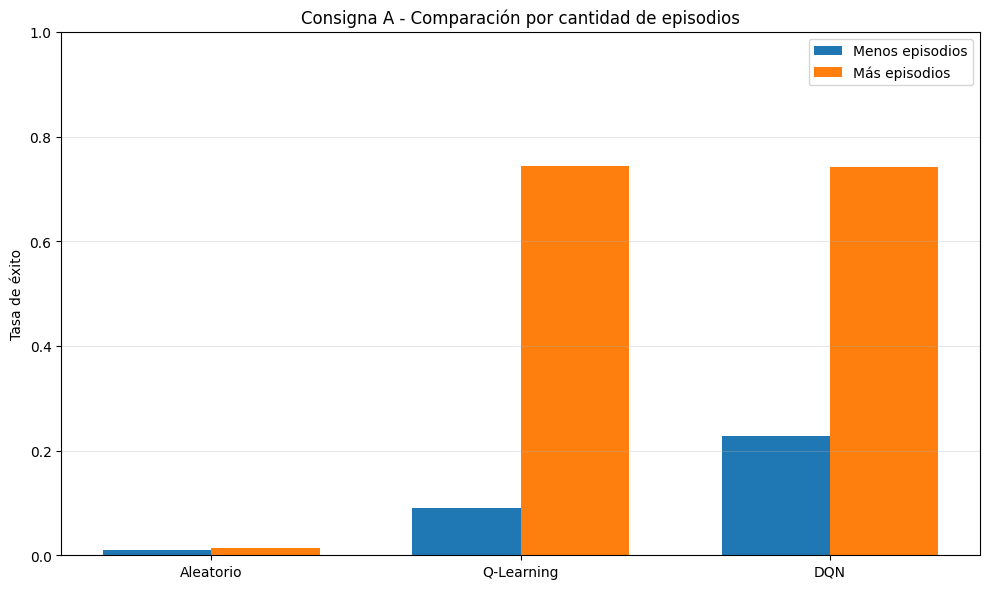

In [20]:

# CONSIGNA A - Comparación final

agentes = ["Aleatorio", "Q-Learning", "DQN"]

exitos_originales = [
    exito_a_1000,
    exito_q_1000,
    exito_dqn_2000
]

exitos_ampliados = [
    exito_a_10000,
    exito_q_10000,
    exito_dqn_4000
]

# Tabla de resultados
print("COMPARACIÓN FINAL - CONSIGNA A")
print("-" * 55)
print(f"{'Agente':<15} {'Inicial':>12} {'Ampliado':>12}")
print("-" * 55)

for i, agente in enumerate(agentes):
    print(
        f"{agente:<15} "
        f"{exitos_originales[i]:>11.1%} "
        f"{exitos_ampliados[i]:>11.1%}"
    )

# Gráfico comparativo
x = np.arange(len(agentes))
ancho = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - ancho/2,
    exitos_originales,
    ancho,
    label="Menos episodios"
)

plt.bar(
    x + ancho/2,
    exitos_ampliados,
    ancho,
    label="Más episodios"
)

plt.xticks(x, agentes)
plt.ylabel("Tasa de éxito")
plt.title("Consigna A - Comparación por cantidad de episodios")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Conclusión – Consigna A

Al aumentar la cantidad de episodios, se observó una mejora importante en los agentes que utilizan aprendizaje por refuerzo.

El agente aleatorio pasó de **1 % a 1,4 %**, una diferencia mínima que se explica por la aleatoriedad, ya que no aprende de sus experiencias.

En cambio, **Q-Learning mejoró del 9 % al 74,4 %**, mientras que **DQN pasó del 22,8 % al 74,1 %**. Esto demuestra que, en nuestro experimento, ambos agentes aprovecharon los episodios adicionales para mejorar sus políticas y tomar mejores decisiones.

Como conclusión, aumentar los episodios permitió obtener mejores resultados tanto con Q-Learning como con DQN. Sin embargo, **más entrenamiento no garantiza siempre un mejor desempeño**, ya que también influyen factores como la exploración, los hiperparámetros y la aleatoriedad del entorno.

## B) Considere modificar el modelo DQN el hiperparámetro gamma: un valor bajo, uno medio y uno alto. Entrene los tres modelos y compare los resultados. Comparta sus conclusiones

# Introducción – Consigna B

En esta consigna vamos a analizar cómo influye el factor de descuento gamma (γ) en el aprendizaje de DQN.

Para ello, entrenamos tres modelos con valores de gamma de 0.50, 0.80 y 0.99, manteniendo constantes los demás hiperparámetros. El objetivo es comparar sus tasas de éxito y observar cómo cambia el desempeño del agente según la importancia que le asigna a las recompensas futuras.

In [18]:

# CONSIGNA B - Comparación de gamma en DQN

gammas_B = [0.50, 0.80, 0.99]
episodios_B = 10000

resultados_B = {}

for gamma in gammas_B:

    print(f"\n{'='*50}")
    print(f"ENTRENANDO DQN CON GAMMA = {gamma}")
    print(f"{'='*50}")

    # Fijar semillas para cada experimento
    np.random.seed(42)
    random.seed(42)
    torch.manual_seed(42)

    # Crear entorno independiente
    env_B = gym.make(
        'FrozenLake-v1',
        map_name='4x4',
        is_slippery=True
    )
    env_B.reset(seed=42)

    # Crear un DQN nuevo para cada gamma
    agente_B = DQNAgent(
        env_B.observation_space.n,
        env_B.action_space.n,
        lr=0.001,
        gamma=gamma,
        epsilon=1.0
    )

    # Entrenar
    agente_B.entrenar(
        env_B, episodios=episodios_B
    )

    # Evaluar usando la función de la consigna A
    tasa_exito = evaluar_A(
        agente_B, episodios=1000
    )

    resultados_B[gamma] = tasa_exito

    env_B.close()

# Mostrar resultados
print("\nRESULTADOS FINALES - CONSIGNA B")
print("-" * 40)

for gamma, exito in resultados_B.items():
    print(f"Gamma = {gamma:.2f} | Éxito = {exito:.1%}")



ENTRENANDO DQN CON GAMMA = 0.5
🖥️ Usando dispositivo: cpu
🤖 Entrenando Deep Q-Network (DQN)...
Episodio 200: Tasa éxito = 0.000, Epsilon = 0.367, Loss = 0.0011
Episodio 400: Tasa éxito = 0.040, Epsilon = 0.135, Loss = 0.0015
Episodio 600: Tasa éxito = 0.060, Epsilon = 0.049, Loss = 0.0015
Episodio 800: Tasa éxito = 0.070, Epsilon = 0.018, Loss = 0.0021
Episodio 1000: Tasa éxito = 0.120, Epsilon = 0.010, Loss = 0.0043
Episodio 1200: Tasa éxito = 0.100, Epsilon = 0.010, Loss = 0.0040
Episodio 1400: Tasa éxito = 0.070, Epsilon = 0.010, Loss = 0.0050
Episodio 1600: Tasa éxito = 0.080, Epsilon = 0.010, Loss = 0.0043
Episodio 1800: Tasa éxito = 0.060, Epsilon = 0.010, Loss = 0.0053
Episodio 2000: Tasa éxito = 0.040, Epsilon = 0.010, Loss = 0.0057
Episodio 2200: Tasa éxito = 0.100, Epsilon = 0.010, Loss = 0.0041
Episodio 2400: Tasa éxito = 0.060, Epsilon = 0.010, Loss = 0.0034
Episodio 2600: Tasa éxito = 0.060, Epsilon = 0.010, Loss = 0.0055
Episodio 2800: Tasa éxito = 0.130, Epsilon = 0.010

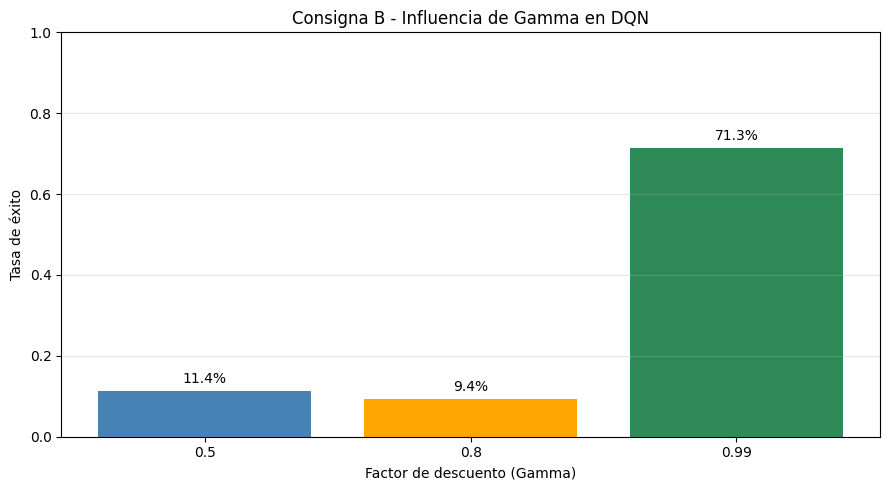

In [21]:

# CONSIGNA B - Gráfico comparativo

valores_gamma = list(resultados_B.keys())
tasas_exito = list(resultados_B.values())

plt.figure(figsize=(9, 5))

barras = plt.bar(
    [str(g) for g in valores_gamma],
    tasas_exito,
    color=['steelblue', 'orange', 'seagreen']
)

plt.title("Consigna B - Influencia de Gamma en DQN")
plt.xlabel("Factor de descuento (Gamma)")
plt.ylabel("Tasa de éxito")
plt.ylim(0, 1)
plt.grid(axis='y', alpha=0.3)

for barra, tasa in zip(barras, tasas_exito):
    plt.text(
        barra.get_x() + barra.get_width()/2,
        tasa + 0.02,
        f"{tasa:.1%}",
        ha='center'
    )

plt.tight_layout()
plt.show()


### Conclusión – Consigna B

Los resultados muestran que el factor de descuento gamma influye considerablemente en el desempeño de DQN.

Con **γ = 0.50** obtuvimos un 11,4 % de éxito y con **γ = 0.80** un 9,4 %. En cambio, con **γ = 0.99** la tasa de éxito aumentó al 71,3 %.

Esto tiene sentido porque en FrozenLake la recompensa se obtiene únicamente al llegar a la meta. Por lo tanto, un gamma alto permite valorar más las recompensas futuras, mientras que con valores bajos estas pierden importancia rápidamente.

En conclusión, **gamma = 0.99 fue el que mejor funcionó en nuestro experimento**, mostrando que valorar las recompensas a largo plazo resulta especialmente importante en este entorno. De todas formas, los resultados también pueden variar por la aleatoriedad del entrenamiento.

## C) Lo mismo que en B) pero para el hiperparámetro alpha.

# Introducción – Consigna C

En esta consigna vamos a analizar cómo influye la tasa de aprendizaje alpha (α) en el desempeño de DQN.

Para ello, entrenamos tres modelos con tasas de aprendizaje bajas, medias y altas, manteniendo constantes los demás hiperparámetros. El objetivo es comparar sus tasas de éxito y observar cómo influye la velocidad de actualización de los pesos de la red neuronal en el aprendizaje.

In [11]:

# CONSIGNA C - Comparación de alpha en DQN

alphas_C = [0.0001, 0.001, 0.01]
episodios_C = 10000

resultados_C = {}

for alpha in alphas_C:

    print(f"\n{'='*50}")
    print(f"ENTRENANDO DQN CON ALPHA = {alpha}")
    print(f"{'='*50}")

    # Fijar semillas para cada experimento
    np.random.seed(42)
    random.seed(42)
    torch.manual_seed(42)

    # Crear entorno independiente
    env_C = gym.make(
        'FrozenLake-v1',
        map_name='4x4',
        is_slippery=True
    )
    env_C.reset(seed=42)

    # Crear un DQN nuevo para cada alpha
    agente_C = DQNAgent(
        env_C.observation_space.n,
        env_C.action_space.n,
        lr=alpha,
        gamma=0.95,
        epsilon=1.0
    )

    # Entrenar durante 10000 episodios
    agente_C.entrenar(
        env_C, episodios=episodios_C
    )

    # Evaluar usando la función de la consigna A
    tasa_exito = evaluar_A(
        agente_C, episodios=1000
    )

    resultados_C[alpha] = tasa_exito

    env_C.close()

# Mostrar resultados
print("\nRESULTADOS FINALES - CONSIGNA C")
print("-" * 40)

for alpha, exito in resultados_C.items():
    print(f"Alpha = {alpha:.4f} | Éxito = {exito:.1%}")



ENTRENANDO DQN CON ALPHA = 0.0001
🖥️ Usando dispositivo: cpu
🤖 Entrenando Deep Q-Network (DQN)...
Episodio 200: Tasa éxito = 0.060, Epsilon = 0.367, Loss = 0.0072
Episodio 400: Tasa éxito = 0.220, Epsilon = 0.135, Loss = 0.0074
Episodio 600: Tasa éxito = 0.250, Epsilon = 0.049, Loss = 0.0069
Episodio 800: Tasa éxito = 0.480, Epsilon = 0.018, Loss = 0.0069
Episodio 1000: Tasa éxito = 0.560, Epsilon = 0.010, Loss = 0.0082
Episodio 1200: Tasa éxito = 0.580, Epsilon = 0.010, Loss = 0.0080
Episodio 1400: Tasa éxito = 0.580, Epsilon = 0.010, Loss = 0.0080
Episodio 1600: Tasa éxito = 0.640, Epsilon = 0.010, Loss = 0.0079
Episodio 1800: Tasa éxito = 0.670, Epsilon = 0.010, Loss = 0.0078
Episodio 2000: Tasa éxito = 0.710, Epsilon = 0.010, Loss = 0.0073
Episodio 2200: Tasa éxito = 0.750, Epsilon = 0.010, Loss = 0.0077
Episodio 2400: Tasa éxito = 0.610, Epsilon = 0.010, Loss = 0.0076
Episodio 2600: Tasa éxito = 0.670, Epsilon = 0.010, Loss = 0.0073
Episodio 2800: Tasa éxito = 0.710, Epsilon = 0.

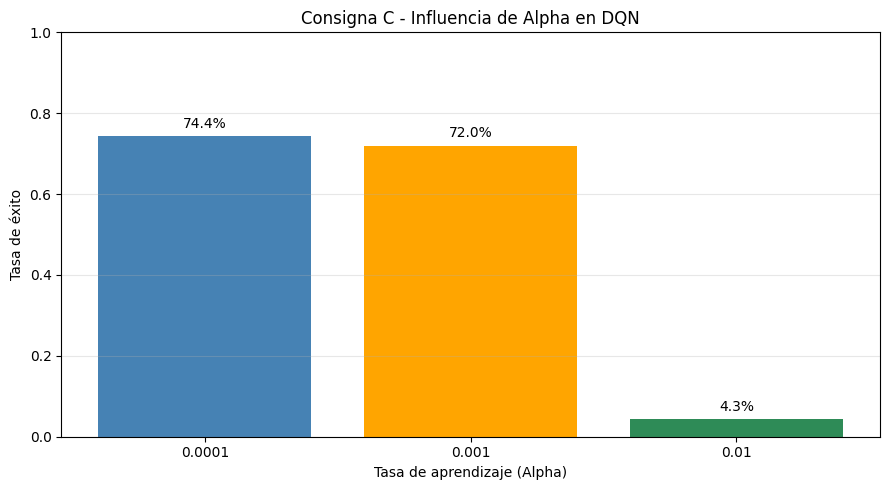

In [12]:

# CONSIGNA C - Gráfico comparativo

valores_alpha = list(resultados_C.keys())
tasas_exito_C = list(resultados_C.values())

plt.figure(figsize=(9, 5))

barras = plt.bar(
    [str(a) for a in valores_alpha],
    tasas_exito_C,
    color=['steelblue', 'orange', 'seagreen']
)

plt.title("Consigna C - Influencia de Alpha en DQN")
plt.xlabel("Tasa de aprendizaje (Alpha)")
plt.ylabel("Tasa de éxito")
plt.ylim(0, 1)
plt.grid(axis='y', alpha=0.3)

for barra, tasa in zip(barras, tasas_exito_C):
    plt.text(
        barra.get_x() + barra.get_width()/2,
        tasa + 0.02,
        f"{tasa:.1%}",
        ha='center'
    )

plt.tight_layout()
plt.show()


### Conclusión – Consigna C

Los resultados muestran que la tasa de aprendizaje alpha influye considerablemente en el desempeño de DQN.

Con **α = 0.0001** obtuvimos un 74,4 % de éxito, mientras que con **α = 0.001** alcanzamos un 72 %. En cambio, al aumentar alpha a **0.01**, la tasa de éxito cayó al 4,3 %.

Esto indica que una tasa de aprendizaje demasiado alta puede generar actualizaciones excesivas en los pesos de la red neuronal, dificultando la estabilidad del entrenamiento. Por otro lado, los valores más bajos permitieron un aprendizaje más estable y mejores resultados.

En conclusión, **alpha = 0.0001 fue el que mejor funcionó en nuestro experimento**, aunque la diferencia con 0.001 fue pequeña. Esto demuestra que aumentar la tasa de aprendizaje no necesariamente mejora el desempeño y que es importante encontrar un equilibrio para lograr un entrenamiento estable.

# Experimento adicional

In [13]:

# EXPERIMENTO ADICIONAL - DQN optimizado

np.random.seed(42)
random.seed(42)
torch.manual_seed(42)

env_opt = gym.make(
    'FrozenLake-v1',
    map_name='4x4',
    is_slippery=True
)
env_opt.reset(seed=42)

# Combinación de los mejores valores individuales
agente_opt = DQNAgent(
    env_opt.observation_space.n,
    env_opt.action_space.n,
    lr=0.0001,
    gamma=0.99,
    epsilon=1.0
)

# Entrenar durante 10000 episodios
agente_opt.entrenar(env_opt, episodios=10000)

# Evaluar sin exploración
exito_opt = evaluar_A(agente_opt, episodios=1000)

env_opt.close()

print("\nEXPERIMENTO ADICIONAL")
print(f"Alpha: 0.0001")
print(f"Gamma: 0.99")
print(f"Tasa de éxito: {exito_opt:.1%}")


🖥️ Usando dispositivo: cpu
🤖 Entrenando Deep Q-Network (DQN)...
Episodio 200: Tasa éxito = 0.010, Epsilon = 0.367, Loss = 0.0078
Episodio 400: Tasa éxito = 0.300, Epsilon = 0.135, Loss = 0.0093
Episodio 600: Tasa éxito = 0.380, Epsilon = 0.049, Loss = 0.0092
Episodio 800: Tasa éxito = 0.520, Epsilon = 0.018, Loss = 0.0051
Episodio 1000: Tasa éxito = 0.750, Epsilon = 0.010, Loss = 0.0054
Episodio 1200: Tasa éxito = 0.650, Epsilon = 0.010, Loss = 0.0051
Episodio 1400: Tasa éxito = 0.730, Epsilon = 0.010, Loss = 0.0048
Episodio 1600: Tasa éxito = 0.650, Epsilon = 0.010, Loss = 0.0056
Episodio 1800: Tasa éxito = 0.720, Epsilon = 0.010, Loss = 0.0055
Episodio 2000: Tasa éxito = 0.750, Epsilon = 0.010, Loss = 0.0050
Episodio 2200: Tasa éxito = 0.710, Epsilon = 0.010, Loss = 0.0047
Episodio 2400: Tasa éxito = 0.690, Epsilon = 0.010, Loss = 0.0059
Episodio 2600: Tasa éxito = 0.660, Epsilon = 0.010, Loss = 0.0053
Episodio 2800: Tasa éxito = 0.690, Epsilon = 0.010, Loss = 0.0054
Episodio 3000: T

### Conclusión – Experimento adicional

Finalmente, combinamos los hiperparámetros que mejores resultados habían obtenido individualmente: **alpha = 0.0001 y gamma = 0.99**.

Después de entrenar DQN durante 10.000 episodios, obtuvimos una tasa de éxito del **74,5 %**, ligeramente superior al 74,4 % alcanzado anteriormente.

Sin embargo, la diferencia fue mínima, por lo que no podemos asegurar que esta combinación sea realmente mejor. La aleatoriedad del entorno también influye en los resultados.

En conclusión, combinar los mejores hiperparámetros individuales permitió mantener un buen rendimiento, pero no produjo una mejora significativa en esta ejecución.

## Referencias bibliográficas

1. **Material de cátedra.** (s. f.). *RL_TP3_entorno_discreto_FrozenLake* [Notebook de Google Colab]. Aprendizaje Automático II.

2. **Farama Foundation.** (s. f.). *Frozen Lake – Gymnasium Documentation*. https://gymnasium.farama.org/environments/toy_text/frozen_lake/

3. **Farama Foundation.** (s. f.). *Solving FrozenLake with Tabular Q-Learning*. https://gymnasium.farama.org/tutorials/training_agents/frozenlake_q_learning/

4. **Sutton, R. S., & Barto, A. G.** (2018). *Reinforcement Learning: An Introduction* (2.ª ed.). MIT Press. https://mitpress.ublish.com/book/reinforcement-learning-an-introduction-2

5. **Paszke, A., & Towers, M.** (2025). *Reinforcement Learning (DQN) Tutorial*. PyTorch. https://docs.pytorch.org/tutorials/intermediate/reinforcement_q_learning.html

6. **Mnih, V., et al.** (2015). *Human-level control through deep reinforcement learning*. Nature, 518, 529–533. https://doi.org/10.1038/nature14236